# CaloDiffusion Electron — Technical Outlier Investigation

**Purpose:** investigate the high-response electron shower, the low-response / broad-radial shower, deep-shower candidates, and whether the localized outer-cell hotspot recurs in other generated events.

This notebook uses the **three existing electron fidelity ZIP files**. It does not load a checkpoint, rerun the sampler, or generate new showers.

## Questions answered
1. Is the response 1.373 event caused by inconsistent units or an obvious decoder scaling mistake?
2. Which cells dominate its deposited energy, and how much does the top cell / top five cells contribute?
3. Is the 0.467-response, broad-radial event driven by one outer-cell hotspot?
4. Does that exact hotspot or the wider outer radial ring recur across all three seeds and energy windows?
5. Are the deep-shower candidates genuine longitudinal outliers relative to the fixed reference samples?
6. Do candidate layer and radial profiles support a local anomaly or a broader population-level effect?

**Important interpretation rule:** removing a cell or shower is used only for sensitivity diagnosis. All main comparisons retain the original, unmodified events.

## Known inputs
- Three generation seeds: `20261110`, `20261111`, `20261112`.
- Fixed reference partition seed: `20261101`.
- Electron analysis threshold: `1.51e-5 GeV` (15.1 keV).
- Native shape: `(45, 16, 9)` = 6,480 cells.
- Saved native arrays and incident energies are in GeV.

The reference/checkpoint training and selection independence is still **unverified**. This notebook records that limitation; it cannot establish provenance from the ZIP files alone.


In [ ]:
# 1. Imports and analysis settings
import io, os, re, json, zipfile, hashlib, urllib.request, textwrap, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ENERGY_WINDOWS = ["8-12GeV", "40-60GeV", "80-120GeV"]
EXPECTED_SEEDS = [20261110, 20261111, 20261112]
PARTITION_SEED = 20261101
BASELINE_SEED = 20261102
ANALYSIS_SEED = 20261103
ANALYSIS_CUT_GEV = 1.51e-5
MAXDEP_EXPECTED = 2.0
N_LAYERS, N_ANGLES, N_RADIAL = 45, 16, 9
N_CELLS = N_LAYERS * N_ANGLES * N_RADIAL

# Exact events selected from the previous closeout, identified by run + stratum + row.
# We resolve the stored event_id from the actual NPZ rather than assuming IDs are globally unique.
CANDIDATES = [
    {"label": "high_response_1p373", "seed": 20261111, "stratum": "8-12GeV", "run": 0, "row": 61,
     "description": "High-response, front-loaded shower (previously reported response ~1.373)."},
    {"label": "low_response_broad_radial_0p467", "seed": 20261111, "stratum": "8-12GeV", "run": 0, "row": 200,
     "description": "Low-response shower with a localized outer radial-bin hotspot (previously reported response ~0.467)."},
    {"label": "deep_8_12", "seed": 20261110, "stratum": "8-12GeV", "run": 1, "row": 58,
     "description": "Deep low-energy candidate."},
    {"label": "deep_40_60", "seed": 20261110, "stratum": "40-60GeV", "run": 0, "row": 113,
     "description": "Deep middle-energy candidate."},
    {"label": "deep_80_120", "seed": 20261112, "stratum": "80-120GeV", "run": 1, "row": 48,
     "description": "Deep high-energy candidate."},
]

# Known hotspot from the low-response event: layer 10, angular bin 13, radial bin 8.
HOTSPOT_COORD = (10, 13, 8)
HOTSPOT_INDEX = (HOTSPOT_COORD[0] * N_ANGLES + HOTSPOT_COORD[1]) * N_RADIAL + HOTSPOT_COORD[2]

print("Electron technical audit settings")
print("Analysis cutoff:", ANALYSIS_CUT_GEV, "GeV")
print("Native shape:", (N_LAYERS, N_ANGLES, N_RADIAL), "cells:", N_CELLS)
print("Hotspot coordinate:", HOTSPOT_COORD, "flat native index:", HOTSPOT_INDEX)


Electron technical audit settings
Analysis cutoff: 1.51e-05 GeV
Native shape: (45, 16, 9) cells: 6480
Hotspot coordinate: (10, 13, 8) flat native index: 1565


## 2. Upload the three fidelity ZIP files

Upload exactly the three electron fidelity ZIP files (generation seeds 20261110, 20261111 and 20261112). Do **not** upload the earlier closeout ZIP in this cell.

In [ ]:
from google.colab import files
uploaded = files.upload()
zip_uploads = {name: data for name, data in uploaded.items() if name.lower().endswith(".zip")}
if len(zip_uploads) != 3:
    raise ValueError(f"Expected exactly 3 fidelity ZIP files; received {len(zip_uploads)}. Upload one ZIP per generation seed.")
print("Uploaded ZIPs:")
for name in zip_uploads:
    print(" -", name)


Saving validated_calo_controlled_electron_partition20261101_generation20261110_20261110T114741139357Z_fidelity_20261110T122654678596Z.zip to validated_calo_controlled_electron_partition20261101_generation20261110_20261110T114741139357Z_fidelity_20261110T122654678596Z.zip
Saving validated_calo_controlled_electron_partition20261101_generation20261111_20261110T122815545026Z_fidelity_20261110T130201775779Z.zip to validated_calo_controlled_electron_partition20261101_generation20261111_20261110T122815545026Z_fidelity_20261110T130201775779Z.zip
Saving validated_calo_controlled_electron_partition20261101_generation20261112_20261110T130357961245Z_fidelity_20261110T140251286095Z.zip to validated_calo_controlled_electron_partition20261101_generation20261112_20261110T130357961245Z_fidelity_20261110T140251286095Z.zip
Uploaded ZIPs:
 - validated_calo_controlled_electron_partition20261101_generation20261110_20261110T114741139357Z_fidelity_20261110T122654678596Z.zip
 - validated_calo_controlled_electr

In [ ]:
# 3. Read manifests, geometry, arrays and tables from each ZIP

def _member(zf, suffix):
    hits = [n for n in zf.namelist() if n.endswith(suffix)]
    if len(hits) != 1:
        raise ValueError(f"Expected exactly one member ending {suffix!r}; found {len(hits)}")
    return hits[0]

def _read_json(zf, suffix):
    return json.loads(zf.read(_member(zf, suffix)).decode("utf-8"))

def _read_csv(zf, suffix):
    return pd.read_csv(io.BytesIO(zf.read(_member(zf, suffix))))

def _read_npz(zf, suffix):
    with np.load(io.BytesIO(zf.read(_member(zf, suffix))), allow_pickle=False) as data:
        return {k: data[k].copy() for k in data.files}

runs = {}
for filename, payload in zip_uploads.items():
    with zipfile.ZipFile(io.BytesIO(payload)) as zf:
        manifest = _read_json(zf, "manifest.json")
        geometry = _read_json(zf, "electron_geometry.json")
        seed = int(manifest["seed_streams"]["generation_seed"])
        if seed in runs:
            raise ValueError(f"Duplicate generation seed {seed}.")
        run = {"manifest": manifest, "geometry": geometry, "arrays": {}, "tables": {}}
        for window in ENERGY_WINDOWS:
            prefix = f"arrays/electron_{window}_"
            run["arrays"][window] = {
                "reference": _read_npz(zf, prefix + "reference_run-1.npz"),
                "generator_run0": _read_npz(zf, prefix + "generator_run0.npz"),
                "generator_run1": _read_npz(zf, prefix + "generator_run1.npz"),
                "scale_only": _read_npz(zf, prefix + "scale_only_run-1.npz"),
            }
            run["tables"][window] = {
                "scale_donors": _read_csv(zf, f"tables/electron_{window}_scale_donors.csv"),
                "generation_stability": _read_csv(zf, f"tables/electron_{window}_generation_run_stability.csv"),
            }
        run["partition_table"] = _read_csv(zf, "tables/electron_event_partitions.csv")
        run["fidelity_summary"] = _read_csv(zf, "tables/fidelity_summary.csv")
        run["fidelity_distances"] = _read_csv(zf, "tables/fidelity_distances.csv")
        run["transform_audit"] = _read_csv(zf, "tables/electron_transform_audit.csv")
        runs[seed] = run

assert sorted(runs) == EXPECTED_SEEDS, f"Expected seeds {EXPECTED_SEEDS}; got {sorted(runs)}"
print("Loaded seeds:", sorted(runs))
for seed in sorted(runs):
    print(seed, "checkpoint:", runs[seed]["manifest"]["checkpoints"]["electron"]["sha256"][:16] + "…")


Loaded seeds: [20261110, 20261111, 20261112]
20261110 checkpoint: cb62afae47997307…
20261111 checkpoint: cb62afae47997307…
20261112 checkpoint: cb62afae47997307…


In [ ]:
# 4. Compatibility and fixed-reference checks
compat_rows = []
base_manifest = runs[EXPECTED_SEEDS[0]]["manifest"]

for seed in EXPECTED_SEEDS:
    m = runs[seed]["manifest"]
    checks = {
        "electron_only": m.get("particles") == ["electron"],
        "same_repository_revision": m.get("revision") == base_manifest.get("revision"),
        "same_checkpoint_hash": m["checkpoints"]["electron"]["sha256"] == base_manifest["checkpoints"]["electron"]["sha256"],
        "same_reference_hash": m["reference_files"]["electron"]["sha256"] == base_manifest["reference_files"]["electron"]["sha256"],
        "same_partition_hash": m["partition_sha256"]["electron"] == base_manifest["partition_sha256"]["electron"],
        "same_scale_donor_hashes": m["scale_donor_sha256"]["electron"] == base_manifest["scale_donor_sha256"]["electron"],
        "same_analysis_cut": m["analysis_cut_GeV_overrides"]["electron"] == ANALYSIS_CUT_GEV,
        "same_partition_seed": m["seed_streams"]["partition_seed"] == PARTITION_SEED,
        "same_baseline_seed": m["seed_streams"]["baseline_seed"] == BASELINE_SEED,
        "same_analysis_seed": m["seed_streams"]["analysis_seed"] == ANALYSIS_SEED,
        "reference_independence_verified": bool(m.get("reference_is_unseen_by_checkpoint", False)),
    }
    for name, passed in checks.items():
        compat_rows.append({"seed": seed, "check": name, "passed": bool(passed)})

# Compare exact partition tables, reference arrays/IDs, donor tables and scale-only arrays.
for seed in EXPECTED_SEEDS[1:]:
    assert runs[seed]["partition_table"].equals(runs[EXPECTED_SEEDS[0]]["partition_table"]), "Partition CSV differs."
    for window in ENERGY_WINDOWS:
        for key in ["reference", "scale_only"]:
            a = runs[EXPECTED_SEEDS[0]]["arrays"][window][key]
            b = runs[seed]["arrays"][window][key]
            assert np.array_equal(a["native"], b["native"]), f"{key} native arrays differ for {window}, seed {seed}."
            assert np.array_equal(a["event_id"], b["event_id"]), f"{key} event IDs differ for {window}, seed {seed}."
        assert runs[seed]["tables"][window]["scale_donors"].equals(
            runs[EXPECTED_SEEDS[0]]["tables"][window]["scale_donors"]
        ), f"Scale donor table differs for {window}."

compatibility = pd.DataFrame(compat_rows)
display(compatibility.pivot(index="check", columns="seed", values="passed"))
print("All checks except provenance should pass. Provenance is explicitly unresolved in the manifests.")


seed,20261110,20261111,20261112
check,,,
electron_only,True,True,True
reference_independence_verified,False,False,False
same_analysis_cut,True,True,True
same_analysis_seed,True,True,True
same_baseline_seed,True,True,True
same_checkpoint_hash,True,True,True
same_partition_hash,True,True,True
same_partition_seed,True,True,True
same_reference_hash,True,True,True


All checks except provenance should pass. Provenance is explicitly unresolved in the manifests.


## 3. Geometry and event-observable helpers

The electron native array is flattened from `(45, 16, 9)` in C-order. The flattened index is `((layer * 16) + angle) * 9 + radial`. The notebook checks this mapping against the geometry saved in the ZIP and uses the XML radial-bin centres to calculate radial moments.

In [ ]:
# 5. Reconstruct the native-cell map from saved geometry
geometry = runs[EXPECTED_SEEDS[0]]["geometry"]
layer_ids = np.asarray(geometry["layer_ids"], dtype=int)
n_angles = np.asarray(geometry["n_angles"], dtype=int)
radial_edges = [np.asarray(x, dtype=float) for x in geometry["radial_edges"]]

assert len(layer_ids) == N_LAYERS
assert np.all(n_angles == N_ANGLES)
assert all(len(edges) - 1 == N_RADIAL for edges in radial_edges)
assert sum(int(a) * (len(e) - 1) for a, e in zip(n_angles, radial_edges)) == N_CELLS

cell_rows = []
for layer in range(N_LAYERS):
    edges = radial_edges[layer]
    centers = 0.5 * (edges[:-1] + edges[1:])
    for angle in range(N_ANGLES):
        for radial in range(N_RADIAL):
            idx = (layer * N_ANGLES + angle) * N_RADIAL + radial
            cell_rows.append({
                "native_index": idx,
                "layer_ordinal": layer,
                "layer_id": int(layer_ids[layer]),
                "angle_index": angle,
                "radial_bin": radial,
                "r_low_XML": edges[radial],
                "r_high_XML": edges[radial + 1],
                "r_center_XML": centers[radial],
            })
cell_map = pd.DataFrame(cell_rows)
assert len(cell_map) == N_CELLS
assert int(cell_map.loc[cell_map.native_index == HOTSPOT_INDEX, "layer_ordinal"].iloc[0]) == 10
assert int(cell_map.loc[cell_map.native_index == HOTSPOT_INDEX, "angle_index"].iloc[0]) == 13
assert int(cell_map.loc[cell_map.native_index == HOTSPOT_INDEX, "radial_bin"].iloc[0]) == 8
print("Verified saved geometry shape:", (N_LAYERS, N_ANGLES, N_RADIAL))
print("Hotspot flat index:", HOTSPOT_INDEX)
display(cell_map.iloc[[HOTSPOT_INDEX]])


Verified saved geometry shape: (45, 16, 9)
Hotspot flat index: 1565


,native_index,layer_ordinal,layer_id,angle_index,radial_bin,r_low_XML,r_high_XML,r_center_XML
1565,1565,10,10,13,8,37.2,41.85,39.525


In [ ]:
# 6. Core observables, all calculated after the electron analysis cutoff
R_CENTERS = np.stack([0.5 * (e[:-1] + e[1:]) for e in radial_edges], axis=0)  # (45,9)
R_GRID = np.broadcast_to(R_CENTERS[:, None, :], (N_LAYERS, N_ANGLES, N_RADIAL))


def threshold_native(native, cut=ANALYSIS_CUT_GEV):
    x = np.asarray(native, dtype=np.float64)
    return np.where(np.isfinite(x) & (x >= cut), x, 0.0)


def metrics_from_native(native, incident_energy, cut=ANALYSIS_CUT_GEV):
    x = threshold_native(native, cut)
    cube = x.reshape(N_LAYERS, N_ANGLES, N_RADIAL)
    total = float(cube.sum())
    e = float(incident_energy)
    if not np.isfinite(e) or e <= 0 or total <= 0:
        return {"deposit_GeV": total, "response": np.nan, "occupancy": 0.0,
                "depth_layer": np.nan, "r_rms": np.nan, "r_sigma": np.nan,
                "max_cell_GeV": float(cube.max()), "top5_fraction": np.nan}
    layer_energy = cube.sum(axis=(1, 2))
    depth = float(np.dot(np.arange(N_LAYERS), layer_energy) / total)
    rmean2 = float(np.sum(cube * (R_GRID ** 2)) / total)
    rmean = float(np.sum(cube * R_GRID) / total)
    r_rms = np.sqrt(rmean2)
    r_sigma = np.sqrt(max(0.0, rmean2 - rmean ** 2))
    flat_desc = np.sort(cube.ravel())[::-1]
    top5 = float(flat_desc[:5].sum() / total)
    return {
        "deposit_GeV": total,
        "response": total / e,
        "occupancy": float(np.count_nonzero(cube) / N_CELLS),
        "depth_layer": depth,
        "r_rms": float(r_rms),
        "r_sigma": float(r_sigma),
        "max_cell_GeV": float(cube.max()),
        "top5_fraction": top5,
    }


def layer_profile(native, cut=ANALYSIS_CUT_GEV):
    x = threshold_native(native, cut).reshape(N_LAYERS, N_ANGLES, N_RADIAL)
    le = x.sum(axis=(1, 2))
    total = le.sum()
    return le / total if total > 0 else np.zeros(N_LAYERS)


def radial_layer_profile(native, cut=ANALYSIS_CUT_GEV):
    x = threshold_native(native, cut).reshape(N_LAYERS, N_ANGLES, N_RADIAL)
    return x.sum(axis=1)  # (layers, radial bins), sum over angle

print("Observable helpers ready.")


Observable helpers ready.


## 4. Technical energy-scaling / decoder audit

The saved `native` arrays and their `energy` arrays are already in GeV. We first verify that the response recomputed from the saved arrays matches the saved event energy. We then inspect the model's inverse-normalisation convention from the **exact repository revision recorded in the manifests**.

For Dataset 2 the configured `MAXDEP` is 2. The inverse transform maps each cell independently back to a non-negative deposited energy proportional to `MAXDEP × incident energy`. There is no final global operation that forces the sum over all cells to equal the incident energy. Therefore, response above 1 is not, by itself, proof of a MeV/GeV error or decoder bug. It is still a model-fidelity anomaly that needs investigation.

In [ ]:
# 7. Fetch pinned source files and verify SHA-256 against the run manifest
# This is a source-code audit only; it does not load a checkpoint or run the model.
import yaml
SOURCE_BASE = "https://raw.githubusercontent.com/Vishal21501/gen-hep-notebooks/" + base_manifest["revision"] + "/capstone/calodiffusion/"
SOURCE_FILES = {
    "config": "paper_code/configs/config_dataset2.json",
    "utils": "paper_code/scripts/utils.py",
    "consts": "paper_code/scripts/consts.py",
}
source_audit_rows = []
source_text = {}

for key, relpath in SOURCE_FILES.items():
    expected = base_manifest.get("source_sha256", {}).get(relpath)
    url = SOURCE_BASE + relpath
    try:
        with urllib.request.urlopen(url, timeout=30) as response:
            content = response.read()
        actual = hashlib.sha256(content).hexdigest()
        source_text[key] = content.decode("utf-8")
        source_audit_rows.append({
            "file": relpath,
            "expected_sha256": expected,
            "downloaded_sha256": actual,
            "matches_manifest": actual == expected,
            "status": "downloaded"
        })
    except Exception as exc:
        source_audit_rows.append({
            "file": relpath,
            "expected_sha256": expected,
            "downloaded_sha256": None,
            "matches_manifest": False,
            "status": f"download unavailable: {type(exc).__name__}: {exc}"
        })

source_audit = pd.DataFrame(source_audit_rows)
display(source_audit)

if "config" in source_text:
    # Use yaml.safe_load instead of json.loads to support single quotes, comments and trailing commas
    model_config = yaml.safe_load(source_text["config"])
    MAXDEP = float(model_config.get("MAXDEP", MAXDEP_EXPECTED))
    assert np.isclose(MAXDEP, MAXDEP_EXPECTED), (
        f"Pinned source MAXDEP={MAXDEP} differs from the pre-inspected expected value {MAXDEP_EXPECTED}."
    )
    print("Pinned Dataset 2 config MAXDEP:", MAXDEP)
    print("Pinned Dataset 2 config ECUT:", model_config.get("ECUT"), "GeV")
    print("Pinned Dataset 2 shape:", model_config.get("SHAPE"))
else:
    MAXDEP = MAXDEP_EXPECTED
    print("WARNING: Could not download pinned config in this runtime.")
    print("Using MAXDEP=2.0, the value previously checked for this exact repository revision.")
    print("The source_hash_audit.csv will record that live source verification was unavailable.")

if "consts" in source_text:
    print("\nRelevant Dataset 2 normalisation constants (source excerpt):")
    txt = source_text["consts"]
    m = re.search(r"dataset2_params\s*=\s*\{[^}]+\}", txt, flags=re.S)
    print(m.group(0) if m else "Could not extract dataset2_params automatically; inspect the pinned consts.py source.")

if "utils" in source_text:
    txt = source_text["utils"]
    ix = txt.find("class ReverseNorm")
    if ix < 0:
        ix = txt.find("def ReverseNorm")
    print("\nReverseNorm source excerpt:")
    print(txt[ix:ix+6500] if ix >= 0 else "ReverseNorm definition not found by simple text search; inspect pinned utils.py.")

,file,expected_sha256,downloaded_sha256,matches_manifest,status
0,paper_code/configs/config_dataset2.json,aada27339b2ee253348d42b5f641da1d857add005c5598...,aada27339b2ee253348d42b5f641da1d857add005c5598...,True,downloaded
1,paper_code/scripts/utils.py,d34325c1fa5029fa436359b8893095e11c12bdb70a27a1...,d34325c1fa5029fa436359b8893095e11c12bdb70a27a1...,True,downloaded
2,paper_code/scripts/consts.py,3fc6312ff243d3f80f1fefc69ce27cf975713652826141...,3fc6312ff243d3f80f1fefc69ce27cf975713652826141...,True,downloaded


Pinned Dataset 2 config MAXDEP: 2.0
Pinned Dataset 2 config ECUT: 1.51e-05 GeV
Pinned Dataset 2 shape: [-1, 45, 16, 9, 1]

Relevant Dataset 2 normalisation constants (source excerpt):
dataset2_params = {
'logit_mean' : -12.8564,
'logit_std' : 1.9123,
'logit_min': -13.8155,
'logit_max' :  0.1153,

'log_mean' : -17.5451,
'log_std' : 4.4086,
'log_min' : -20.0,
'log_max' :  -0.6372,


'sqrt_mean' : 0.0026,
'sqrt_std' : 0.0073,
'sqrt_min' : 0.,
'sqrt_max' : 1.0,

'qt' : 'qts/dset2_quantile_transform.gz',
}

ReverseNorm source excerpt:
def ReverseNorm(voxels,e,shape,emax,emin,max_deposit=2,logE=True, showerMap ='log', dataset_num = 2, orig_shape = False, ecut = 0.):
    '''Revert the transformations applied to the training set'''

    if(dataset_num > 3 or dataset_num <0 ): 
        print("Invalid dataset %i!" % dataset_num)
        exit(1)
    if(orig_shape and dataset_num <= 1): dataset_num +=10 
    print('dset', dataset_num)
    c = dataset_params[dataset_num]

    #shape=voxels.shape
  

In [ ]:
# 8. Resolve exact events from saved arrays and verify their identifiers

def load_event(seed, stratum, run_index, row_index):
    arr = runs[seed]["arrays"][stratum][f"generator_run{run_index}"]
    if not (0 <= row_index < len(arr["native"])):
        raise IndexError(f"Row {row_index} outside array length {len(arr['native'])}")
    return {
        "seed": seed, "stratum": stratum, "run": run_index, "row": row_index,
        "event_id": str(arr["event_id"][row_index]),
        "native": arr["native"][row_index].astype(np.float64),
        "energy": float(arr["energy"][row_index]),
    }

candidate_events = {}
for spec in CANDIDATES:
    ev = load_event(spec["seed"], spec["stratum"], spec["run"], spec["row"])
    candidate_events[spec["label"]] = {**spec, **ev}

candidate_id_table = pd.DataFrame([
    {k: ev[k] for k in ["label", "seed", "stratum", "run", "row", "event_id", "energy", "description"]}
    for ev in candidate_events.values()
])
display(candidate_id_table)


,label,seed,stratum,run,row,event_id,energy,description
0,high_response_1p373,20261111,8-12GeV,0,61,gen:electron:8-12GeV:0:61,9.771068,"High-response, front-loaded shower (previously..."
1,low_response_broad_radial_0p467,20261111,8-12GeV,0,200,gen:electron:8-12GeV:0:200,8.448531,Low-response shower with a localized outer rad...
2,deep_8_12,20261110,8-12GeV,1,58,gen:electron:8-12GeV:1:58,10.399022,Deep low-energy candidate.
3,deep_40_60,20261110,40-60GeV,0,113,gen:electron:40-60GeV:0:113,43.047789,Deep middle-energy candidate.
4,deep_80_120,20261112,80-120GeV,1,48,gen:electron:80-120GeV:1:48,114.937406,Deep high-energy candidate.


In [ ]:
# 9. Calculate candidate observables and reference envelopes

def reference_native(seed, stratum):
    return runs[seed]["arrays"][stratum]["reference"]


def reference_metric_values(seed, stratum):
    ref = reference_native(seed, stratum)
    vals = [metrics_from_native(x, e) for x, e in zip(ref["native"], ref["energy"])]
    return pd.DataFrame(vals)

candidate_metric_rows = []
reference_metric_cache = {}
for label, ev in candidate_events.items():
    refdf = reference_metric_cache.setdefault(ev["stratum"], reference_metric_values(EXPECTED_SEEDS[0], ev["stratum"]))
    met = metrics_from_native(ev["native"], ev["energy"])
    row = {"label": label, "seed": ev["seed"], "stratum": ev["stratum"],
           "run": ev["run"], "row": ev["row"], "event_id": ev["event_id"],
           "incident_GeV": ev["energy"], **met}
    for metric in ["response", "occupancy", "depth_layer", "r_rms", "r_sigma", "max_cell_GeV"]:
        x = refdf[metric].dropna().to_numpy()
        row[f"ref_{metric}_q01"] = np.quantile(x, 0.01)
        row[f"ref_{metric}_median"] = np.quantile(x, 0.50)
        row[f"ref_{metric}_q99"] = np.quantile(x, 0.99)
        row[f"ref_{metric}_min"] = np.min(x)
        row[f"ref_{metric}_max"] = np.max(x)
        row[f"ref_percentile_{metric}"] = 100.0 * np.mean(x <= met[metric])
    candidate_metric_rows.append(row)

candidate_metrics = pd.DataFrame(candidate_metric_rows)
display(candidate_metrics.round(6))


,label,seed,stratum,run,row,event_id,incident_GeV,deposit_GeV,response,occupancy,...,ref_r_sigma_q99,ref_r_sigma_min,ref_r_sigma_max,ref_percentile_r_sigma,ref_max_cell_GeV_q01,ref_max_cell_GeV_median,ref_max_cell_GeV_q99,ref_max_cell_GeV_min,ref_max_cell_GeV_max,ref_percentile_max_cell_GeV
0,high_response_1p373,20261111,8-12GeV,0,61,gen:electron:8-12GeV:0:61,9.771068,13.418580,1.373297,0.065123,...,11.769986,5.079996,12.476017,48.000000,0.084458,0.170778,0.838611,0.074654,1.254256,100.000000
1,low_response_broad_radial_0p467,20261111,8-12GeV,0,200,gen:electron:8-12GeV:0:200,8.448531,3.942201,0.466614,0.038889,...,11.769986,5.079996,12.476017,100.000000,0.084458,0.170778,0.838611,0.074654,1.254256,99.000000
2,deep_8_12,20261110,8-12GeV,1,58,gen:electron:8-12GeV:1:58,10.399022,7.643424,0.735014,0.079167,...,11.769986,5.079996,12.476017,0.666667,0.084458,0.170778,0.838611,0.074654,1.254256,12.666667
3,deep_40_60,20261110,40-60GeV,0,113,gen:electron:40-60GeV:0:113,43.047789,32.110019,0.745916,0.218519,...,9.998181,6.646130,10.977016,90.333333,0.236200,0.449683,1.640977,0.217323,2.383591,43.333333
4,deep_80_120,20261112,80-120GeV,1,48,gen:electron:80-120GeV:1:48,114.937406,90.051398,0.783482,0.347685,...,9.420579,6.910333,9.806062,49.666667,0.355122,0.646483,1.892389,0.315843,2.017335,68.000000


## 5. High-response shower: energy-scaling audit

The central checks are:
- Does `sum(native) / incident_energy` reproduce the reported response?
- Is the saved array in GeV, with incident energy also in GeV?
- What fraction of the nominal per-cell scale `MAXDEP × E` is used by the largest cell and by all cells combined?
- Do a few cells dominate the over-response?

A large total response is not necessarily a unit-conversion bug. The model produces cell-level values; the sum across many cells is not globally constrained to equal the incident energy. The archive does not contain the pre-decoder latent tensor, so a full sampler-to-decoder replay cannot be performed from these ZIPs alone.

In [ ]:
# 10. High-response event: check response arithmetic and normalized cell fractions
high = candidate_events["high_response_1p373"]
high_native = threshold_native(high["native"])
high_E = high["energy"]
high_deposit = float(high_native.sum())
high_response = high_deposit / high_E
per_cell_scale = MAXDEP * high_E
cell_fractions = high_native / per_cell_scale
positive = np.flatnonzero(high_native > 0)
order = positive[np.argsort(high_native[positive])[::-1]]

high_scaling_summary = pd.DataFrame([{
    "event_id": high["event_id"],
    "incident_energy_GeV": high_E,
    "deposited_energy_after_cut_GeV": high_deposit,
    "response_recomputed": high_response,
    "MAXDEP": MAXDEP,
    "MAXDEP_times_incident_GeV": per_cell_scale,
    "sum_of_normalized_cell_fractions": float(cell_fractions.sum()),
    "response_divided_by_MAXDEP": high_response / MAXDEP,
    "largest_cell_GeV": float(high_native.max()),
    "largest_cell_fraction_of_MAXDEP_times_E": float(cell_fractions.max()),
    "number_of_positive_cells_after_cut": int(np.count_nonzero(high_native)),
    "sum_matches_response_identity": bool(np.isclose(high_deposit / high_E, high_response)),
    "max_cell_fraction_below_one": bool(np.max(cell_fractions) < 1.0),
}])
display(high_scaling_summary.T)

# Top-cell table with verified native coordinates.
top_rows = []
for idx in order[:15]:
    cell = cell_map.iloc[int(idx)]
    top_rows.append({
        "native_index": int(idx),
        "layer": int(cell.layer_ordinal),
        "angle": int(cell.angle_index),
        "radial_bin": int(cell.radial_bin),
        "r_low_XML": float(cell.r_low_XML),
        "r_high_XML": float(cell.r_high_XML),
        "energy_GeV": float(high_native[idx]),
        "fraction_of_total_deposit": float(high_native[idx] / high_deposit),
        "fraction_of_MAXDEP_times_E": float(cell_fractions[idx]),
    })
top_cells_high = pd.DataFrame(top_rows)
print("Top 15 cells in the high-response shower:")
display(top_cells_high)

for k in [1, 5, 10]:
    removed = float(high_native[order[:k]].sum())
    print(f"Diagnostic only — remove top {k} cell(s): response would be {(high_deposit-removed)/high_E:.6f}")


,0
event_id,gen:electron:8-12GeV:0:61
incident_energy_GeV,9.771068
deposited_energy_after_cut_GeV,13.41858
response_recomputed,1.373297
MAXDEP,2.0
MAXDEP_times_incident_GeV,19.542137
sum_of_normalized_cell_fractions,0.686649
response_divided_by_MAXDEP,0.686649
largest_cell_GeV,2.545314
largest_cell_fraction_of_MAXDEP_times_E,0.130247


Top 15 cells in the high-response shower:


,native_index,layer,angle,radial_bin,r_low_XML,r_high_XML,energy_GeV,fraction_of_total_deposit,fraction_of_MAXDEP_times_E
0,118,0,13,1,4.65,9.30,2.545314,0.189686,0.130247
1,831,5,12,3,13.95,18.60,1.107875,0.082563,0.056692
2,117,0,13,0,0.00,4.65,1.050020,0.078251,0.053731
3,2265,15,11,6,27.90,32.55,0.203844,0.015191,0.010431
4,1624,11,4,4,18.60,23.25,0.183007,0.013638,0.009365
5,855,5,15,0,0.00,4.65,0.156635,0.011673,0.008015
6,758,5,4,2,9.30,13.95,0.135395,0.010090,0.006928
7,801,5,9,0,0.00,4.65,0.132733,0.009892,0.006792
8,513,3,9,0,0.00,4.65,0.129710,0.009666,0.006637
9,830,5,12,2,9.30,13.95,0.129427,0.009645,0.006623


Diagnostic only — remove top 1 cell(s): response would be 1.112802
Diagnostic only — remove top 5 cell(s): response would be 0.852365
Diagnostic only — remove top 10 cell(s): response would be 0.782373


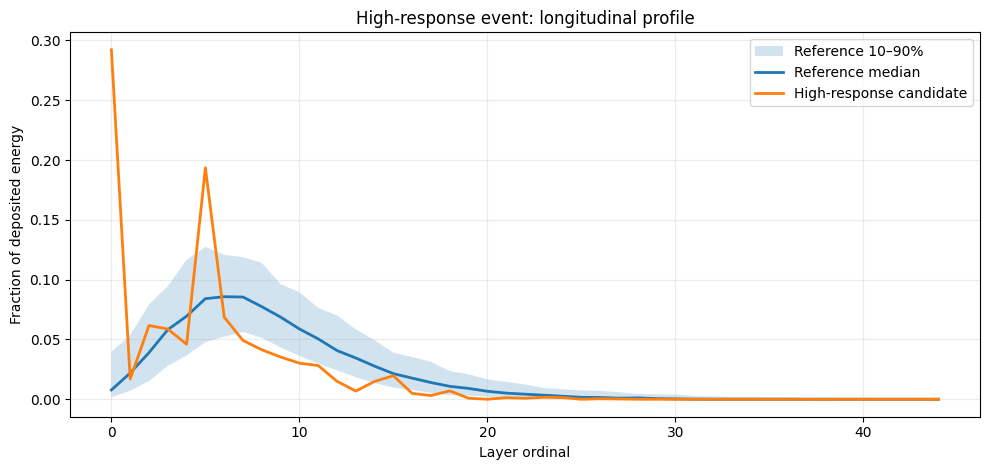

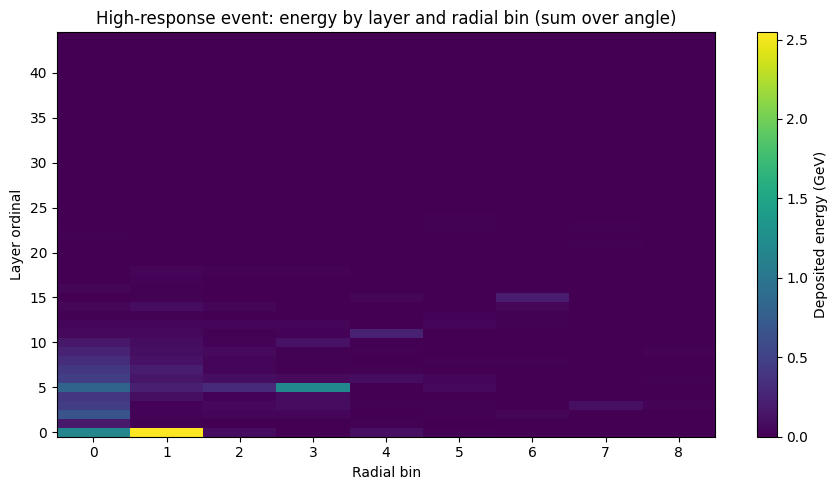

In [ ]:
# 11. High-response shower: 45-layer profile and radial-by-layer map
high_profile = layer_profile(high["native"])
high_radial_map = radial_layer_profile(high["native"])
ref_high = reference_native(EXPECTED_SEEDS[0], high["stratum"])
ref_high_profiles = np.stack([layer_profile(x) for x in ref_high["native"]])

fig, ax = plt.subplots(figsize=(10, 4.8))
layer_x = np.arange(N_LAYERS)
ax.fill_between(layer_x, np.quantile(ref_high_profiles, .10, axis=0),
                np.quantile(ref_high_profiles, .90, axis=0), alpha=.2, label="Reference 10–90%")
ax.plot(layer_x, np.median(ref_high_profiles, axis=0), label="Reference median", linewidth=2)
ax.plot(layer_x, high_profile, label="High-response candidate", linewidth=2)
ax.set(xlabel="Layer ordinal", ylabel="Fraction of deposited energy", title="High-response event: longitudinal profile")
ax.grid(alpha=.25); ax.legend(); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(high_radial_map, aspect="auto", origin="lower", interpolation="nearest")
ax.set(xlabel="Radial bin", ylabel="Layer ordinal", title="High-response event: energy by layer and radial bin (sum over angle)")
fig.colorbar(im, ax=ax, label="Deposited energy (GeV)")
plt.tight_layout(); plt.show()


## 6. Low-response / broad-radial shower: hotspot sensitivity

The candidate was previously identified at native coordinate `(layer=10, angle=13, radial=8)`, flat index 1565. The next cell verifies this directly from the geometry map and quantifies how much this one cell and the entire outer radial bin contribute to the event's radial RMS.

**The removal calculations are counterfactual diagnostics only. The original shower is retained in every main distribution.**

In [ ]:
# 12. Low-response candidate: exact cell, top deposits, radial sensitivity
low = candidate_events["low_response_broad_radial_0p467"]
low_native = threshold_native(low["native"])
low_cube = low_native.reshape(N_LAYERS, N_ANGLES, N_RADIAL)
low_total = low_cube.sum()

idx = HOTSPOT_INDEX
hotspot_meta = cell_map.iloc[idx]
assert (int(hotspot_meta.layer_ordinal), int(hotspot_meta.angle_index), int(hotspot_meta.radial_bin)) == HOTSPOT_COORD


def radial_rms_from_flat(native):
    cube = threshold_native(native).reshape(N_LAYERS, N_ANGLES, N_RADIAL)
    total = cube.sum()
    if total <= 0: return np.nan
    return float(np.sqrt(np.sum(cube * (R_GRID ** 2)) / total))

original_rms = radial_rms_from_flat(low["native"])
without_hotspot = low_native.copy(); without_hotspot[idx] = 0.0
without_outer_bin = low_cube.copy(); without_outer_bin[:, :, 8] = 0.0

low_sensitivity = pd.DataFrame([
    {"case": "Original shower", "deposit_GeV": low_total, "response": low_total/low["energy"], "r_rms_XML": original_rms},
    {"case": "Diagnostic: remove exact hotspot cell only", "deposit_GeV": low_total-low_native[idx],
     "response": (low_total-low_native[idx])/low["energy"], "r_rms_XML": radial_rms_from_flat(without_hotspot)},
    {"case": "Diagnostic: remove radial bin 8 in all layers", "deposit_GeV": without_outer_bin.sum(),
     "response": without_outer_bin.sum()/low["energy"], "r_rms_XML": float(np.sqrt(np.sum(without_outer_bin*R_GRID**2)/without_outer_bin.sum()))},
])
display(pd.DataFrame([{
    "event_id": low["event_id"], "native_index": idx,
    "layer": int(hotspot_meta.layer_ordinal), "angle": int(hotspot_meta.angle_index),
    "radial_bin": int(hotspot_meta.radial_bin), "r_low_XML": hotspot_meta.r_low_XML,
    "r_high_XML": hotspot_meta.r_high_XML, "hotspot_energy_GeV": low_native[idx],
    "hotspot_fraction_of_total": low_native[idx]/low_total
}]))
display(low_sensitivity)

low_order = np.argsort(low_native)[::-1]
low_top = []
for cell_idx in low_order[:15]:
    cell = cell_map.iloc[int(cell_idx)]
    low_top.append({"native_index": int(cell_idx), "layer": int(cell.layer_ordinal),
                    "angle": int(cell.angle_index), "radial_bin": int(cell.radial_bin),
                    "r_low_XML": cell.r_low_XML, "r_high_XML": cell.r_high_XML,
                    "energy_GeV": low_native[cell_idx],
                    "fraction_of_total": low_native[cell_idx]/low_total})
low_top_cells = pd.DataFrame(low_top)
print("Top 15 cells in the low-response / broad-radial shower:")
display(low_top_cells)


,event_id,native_index,layer,angle,radial_bin,r_low_XML,r_high_XML,hotspot_energy_GeV,hotspot_fraction_of_total
0,gen:electron:8-12GeV:0:200,1565,10,13,8,37.2,41.85,0.882544,0.223871


,case,deposit_GeV,response,r_rms_XML
0,Original shower,3.942201,0.466614,23.429949
1,Diagnostic: remove exact hotspot cell only,3.059657,0.362153,16.021592
2,Diagnostic: remove radial bin 8 in all layers,2.905083,0.343857,13.683066


Top 15 cells in the low-response / broad-radial shower:


,native_index,layer,angle,radial_bin,r_low_XML,r_high_XML,energy_GeV,fraction_of_total
0,1565,10,13,8,37.20,41.85,0.882544,0.223871
1,226,1,9,1,4.65,9.30,0.166748,0.042298
2,612,4,4,0,0.00,4.65,0.100901,0.025595
3,180,1,4,0,0.00,4.65,0.099946,0.025353
4,516,3,9,3,13.95,18.60,0.071744,0.018199
5,40,0,4,4,18.60,23.25,0.071008,0.018012
6,603,4,3,0,0.00,4.65,0.067132,0.017029
7,1297,9,0,1,4.65,9.30,0.065814,0.016695
8,2337,16,3,6,27.90,32.55,0.062021,0.015733
9,684,4,12,0,0.00,4.65,0.061989,0.015724


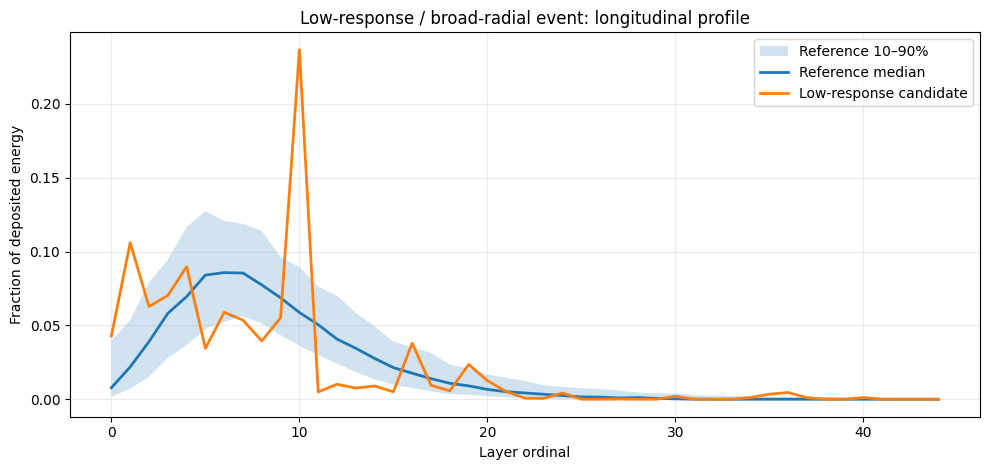

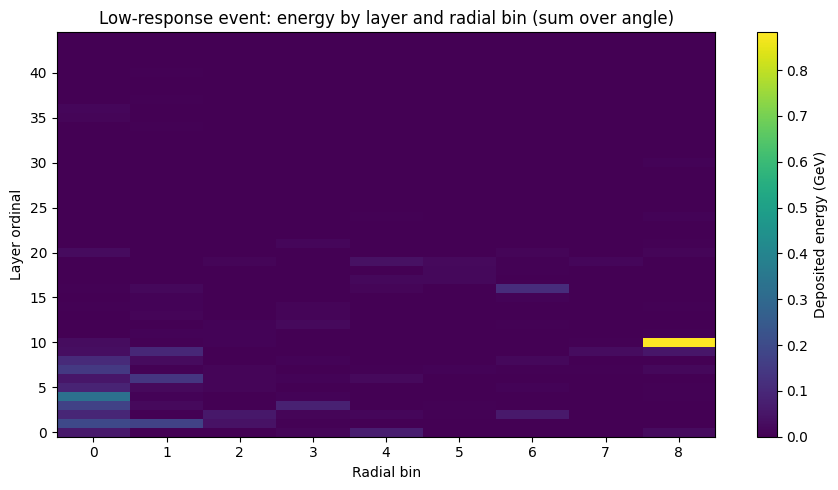

In [ ]:
# 13. Plot low-response event layer/radial map
low_profile = layer_profile(low["native"])
ref_low = reference_native(EXPECTED_SEEDS[0], low["stratum"])
ref_low_profiles = np.stack([layer_profile(x) for x in ref_low["native"]])
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.fill_between(np.arange(N_LAYERS), np.quantile(ref_low_profiles, .10, axis=0),
                np.quantile(ref_low_profiles, .90, axis=0), alpha=.2, label="Reference 10–90%")
ax.plot(np.median(ref_low_profiles, axis=0), label="Reference median", linewidth=2)
ax.plot(low_profile, label="Low-response candidate", linewidth=2)
ax.set(xlabel="Layer ordinal", ylabel="Fraction of deposited energy", title="Low-response / broad-radial event: longitudinal profile")
ax.grid(alpha=.25); ax.legend(); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(radial_layer_profile(low["native"]), aspect="auto", origin="lower", interpolation="nearest")
ax.set(xlabel="Radial bin", ylabel="Layer ordinal", title="Low-response event: energy by layer and radial bin (sum over angle)")
fig.colorbar(im, ax=ax, label="Deposited energy (GeV)")
plt.tight_layout(); plt.show()


## 7. Does the outer-cell hotspot recur?

We compare three increasingly broad definitions:
1. **Exact cell:** `(layer 10, angle 13, radial 8)`, flat index 1565.
2. **Layer-10 outer radial ring:** radial bin 8 across all 16 angles in layer 10.
3. **Whole outer radial shell:** radial bin 8 across all 45 layers and all 16 angles.

For each method and energy window we report event rates above fixed diagnostic thresholds, plus quantiles and maxima. Rates are calculated with the same 15.1 keV analysis threshold. The generated sample pools both generation repeats across all three seeds (1,800 events per energy window); reference and scale-only each contain 300 events.


In [ ]:
# 14. Aggregate recurrence statistics across all three seeds

def collect_method_arrays(window, method):
    if method == "reference":
        return runs[EXPECTED_SEEDS[0]]["arrays"][window]["reference"]["native"]
    if method == "scale_only":
        return runs[EXPECTED_SEEDS[0]]["arrays"][window]["scale_only"]["native"]
    if method == "generator":
        blocks = []
        for seed in EXPECTED_SEEDS:
            for r in [0, 1]:
                blocks.append(runs[seed]["arrays"][window][f"generator_run{r}"]["native"])
        return np.concatenate(blocks, axis=0)
    raise ValueError(method)

recurrence_rows = []
recurrence_samples = {}
for window in ENERGY_WINDOWS:
    for method in ["reference", "generator", "scale_only"]:
        native = threshold_native(collect_method_arrays(window, method))
        cube = native.reshape(-1, N_LAYERS, N_ANGLES, N_RADIAL)
        exact = cube[:, HOTSPOT_COORD[0], HOTSPOT_COORD[1], HOTSPOT_COORD[2]]
        layer10_ring = cube[:, 10, :, 8].max(axis=1)
        whole_shell = cube[:, :, :, 8].sum(axis=(1, 2))
        recurrence_samples[(window, method)] = {"exact": exact, "layer10_ring_max": layer10_ring, "whole_shell_sum": whole_shell}
        for observable, values, thresholds in [
            ("exact_cell_GeV", exact, [0.1, 0.25, 0.5, 0.8, 1.0, 2.0]),
            ("layer10_radial8_max_over_angles_GeV", layer10_ring, [0.1, 0.25, 0.5, 0.8, 1.0, 2.0]),
            ("whole_outer_shell_sum_GeV", whole_shell, [0.1, 0.25, 0.5, 0.8, 1.0, 2.0]),
        ]:
            row = {"energy_window": window, "method": method, "observable": observable,
                   "n": len(values), "mean_GeV": np.mean(values), "q95_GeV": np.quantile(values, .95),
                   "q99_GeV": np.quantile(values, .99), "maximum_GeV": np.max(values)}
            for threshold in thresholds:
                row[f"rate_ge_{threshold:g}_GeV"] = np.mean(values >= threshold)
                row[f"count_ge_{threshold:g}_GeV"] = int(np.sum(values >= threshold))
            recurrence_rows.append(row)

hotspot_recurrence = pd.DataFrame(recurrence_rows)
display(hotspot_recurrence.round(6))


,energy_window,method,observable,n,mean_GeV,q95_GeV,q99_GeV,maximum_GeV,rate_ge_0.1_GeV,count_ge_0.1_GeV,rate_ge_0.25_GeV,count_ge_0.25_GeV,rate_ge_0.5_GeV,count_ge_0.5_GeV,rate_ge_0.8_GeV,count_ge_0.8_GeV,rate_ge_1_GeV,count_ge_1_GeV,rate_ge_2_GeV,count_ge_2_GeV
0,8-12GeV,reference,exact_cell_GeV,300,0.000009,0.000000,0.000029,0.001442,0.000000,0,0.000000,0,0.000000,0,0.000000,0,0.000000,0,0.000000,0
1,8-12GeV,reference,layer10_radial8_max_over_angles_GeV,300,0.002088,0.013467,0.030534,0.036964,0.000000,0,0.000000,0,0.000000,0,0.000000,0,0.000000,0,0.000000,0
2,8-12GeV,reference,whole_outer_shell_sum_GeV,300,0.088955,0.261587,0.488603,0.759105,0.296667,89,0.060000,18,0.010000,3,0.000000,0,0.000000,0,0.000000,0
3,8-12GeV,generator,exact_cell_GeV,1800,0.000634,0.000000,0.002199,0.882544,0.000556,1,0.000556,1,0.000556,1,0.000556,1,0.000000,0,0.000000,0
4,8-12GeV,generator,layer10_radial8_max_over_angles_GeV,1800,0.003340,0.016466,0.044700,0.882544,0.002222,4,0.000556,1,0.000556,1,0.000556,1,0.000000,0,0.000000,0
5,8-12GeV,generator,whole_outer_shell_sum_GeV,1800,0.077460,0.199305,0.400284,1.570795,0.232222,418,0.027222,49,0.005000,9,0.001667,3,0.001111,2,0.000000,0
6,8-12GeV,scale_only,exact_cell_GeV,300,0.000175,0.000831,0.003821,0.006828,0.000000,0,0.000000,0,0.000000,0,0.000000,0,0.000000,0,0.000000,0
7,8-12GeV,scale_only,layer10_radial8_max_over_angles_GeV,300,0.002985,0.009963,0.022183,0.114175,0.003333,1,0.000000,0,0.000000,0,0.000000,0,0.000000,0,0.000000,0
8,8-12GeV,scale_only,whole_outer_shell_sum_GeV,300,0.091046,0.171101,0.202487,0.255171,0.326667,98,0.003333,1,0.000000,0,0.000000,0,0.000000,0,0.000000,0
9,40-60GeV,reference,exact_cell_GeV,300,0.000907,0.004794,0.019603,0.060654,0.000000,0,0.000000,0,0.000000,0,0.000000,0,0.000000,0,0.000000,0


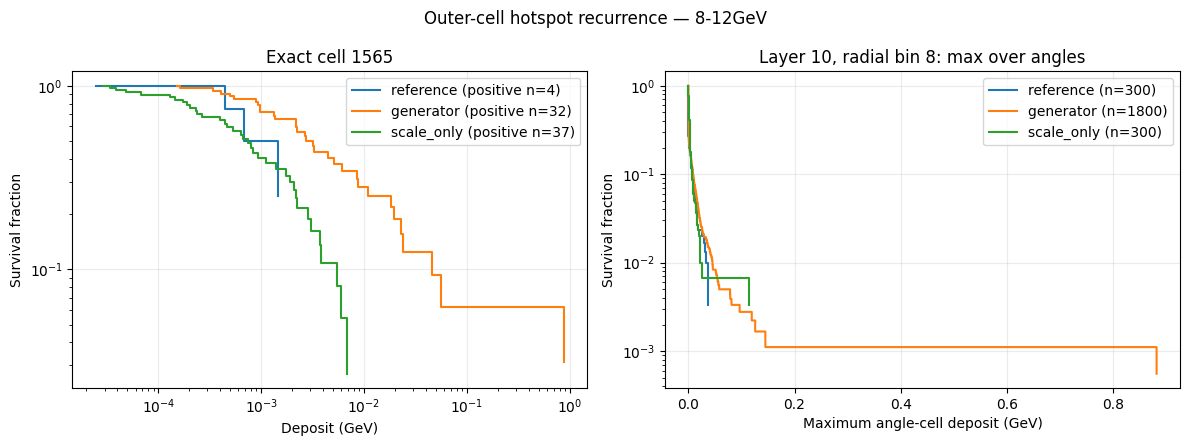

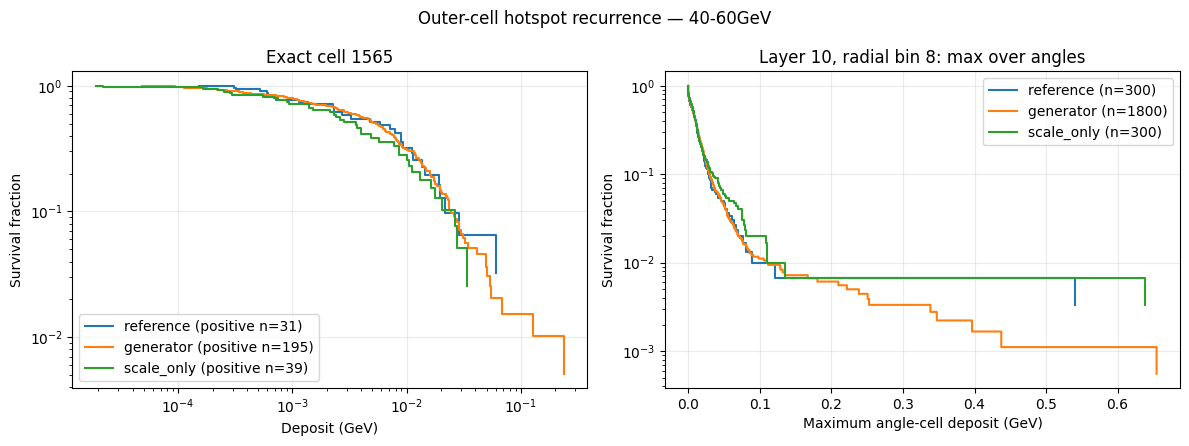

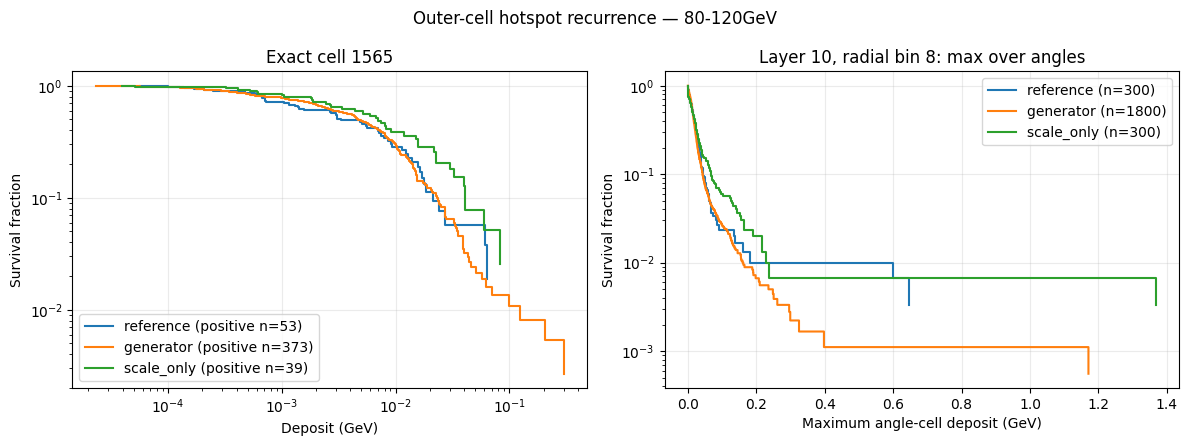

In [ ]:
# 15. Visualise exact-cell and layer-10-ring tails by energy
for window in ENERGY_WINDOWS:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for method in ["reference", "generator", "scale_only"]:
        x = recurrence_samples[(window, method)]["exact"]
        positive = np.sort(x[x > 0])
        if positive.size:
            survival = np.arange(len(positive), 0, -1) / len(positive)
            axes[0].step(positive, survival, where="post", label=f"{method} (positive n={len(positive)})")
        y = np.sort(recurrence_samples[(window, method)]["layer10_ring_max"])
        surv = np.arange(len(y), 0, -1) / len(y)
        axes[1].step(y, surv, where="post", label=f"{method} (n={len(y)})")
    axes[0].set_xscale("log"); axes[0].set_yscale("log")
    axes[0].set(title=f"Exact cell {HOTSPOT_INDEX}", xlabel="Deposit (GeV)", ylabel="Survival fraction")
    axes[1].set_yscale("log")
    axes[1].set(title="Layer 10, radial bin 8: max over angles", xlabel="Maximum angle-cell deposit (GeV)", ylabel="Survival fraction")
    for ax in axes: ax.grid(alpha=.25); ax.legend()
    fig.suptitle(f"Outer-cell hotspot recurrence — {window}")
    plt.tight_layout(); plt.show()


## 8. Deep-shower candidates

For each candidate, compare its 45-layer energy fractions with the 300 fixed reference showers in the same energy window. We report the reference median, 10th–90th percentile band, and candidate depth percentile. A candidate beyond the reference 99th percentile is a statistical tail event; it is not automatically physically impossible.

In [ ]:
# 16. Candidate depth summaries and reference layer-profile envelopes
candidate_depth_rows = []
for label, ev in candidate_events.items():
    ref = reference_native(EXPECTED_SEEDS[0], ev["stratum"])
    ref_metrics = [metrics_from_native(x, e) for x, e in zip(ref["native"], ref["energy"])]
    ref_depth = np.array([x["depth_layer"] for x in ref_metrics], dtype=float)
    met = metrics_from_native(ev["native"], ev["energy"])
    candidate_depth_rows.append({
        "label": label, "seed": ev["seed"], "energy_window": ev["stratum"],
        "event_id": ev["event_id"], "response": met["response"],
        "depth_layer": met["depth_layer"], "reference_depth_median": np.median(ref_depth),
        "reference_depth_q95": np.quantile(ref_depth, .95),
        "reference_depth_q99": np.quantile(ref_depth, .99),
        "reference_depth_max": np.max(ref_depth),
        "candidate_depth_percentile": 100*np.mean(ref_depth <= met["depth_layer"]),
        "r_rms_XML": met["r_rms"],
        "reference_r_rms_q99": np.quantile([x["r_rms"] for x in ref_metrics], .99),
    })

depth_summary = pd.DataFrame(candidate_depth_rows)
display(depth_summary.round(5))


,label,seed,energy_window,event_id,response,depth_layer,reference_depth_median,reference_depth_q95,reference_depth_q99,reference_depth_max,candidate_depth_percentile,r_rms_XML,reference_r_rms_q99
0,high_response_1p373,20261111,8-12GeV,gen:electron:8-12GeV:0:61,1.37330,4.66541,8.55185,11.36588,13.36518,31.94352,0.00000,11.58782,16.93749
1,low_response_broad_radial_0p467,20261111,8-12GeV,gen:electron:8-12GeV:0:200,0.46661,7.64082,8.55185,11.36588,13.36518,31.94352,20.00000,23.42995,16.93749
2,deep_8_12,20261110,8-12GeV,gen:electron:8-12GeV:1:58,0.73501,22.52775,8.55185,11.36588,13.36518,31.94352,99.66667,7.12754,16.93749
3,deep_40_60,20261110,40-60GeV,gen:electron:40-60GeV:0:113,0.74592,16.84559,10.56014,12.73755,14.36210,15.38541,100.00000,12.39080,13.33353
4,deep_80_120,20261112,80-120GeV,gen:electron:80-120GeV:1:48,0.78348,16.71212,11.56692,13.56813,14.62456,16.03209,100.00000,11.02345,12.66058


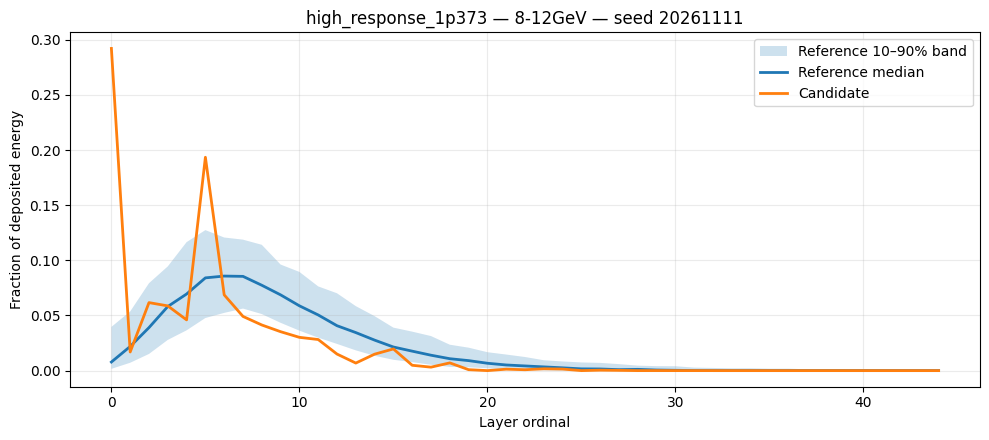

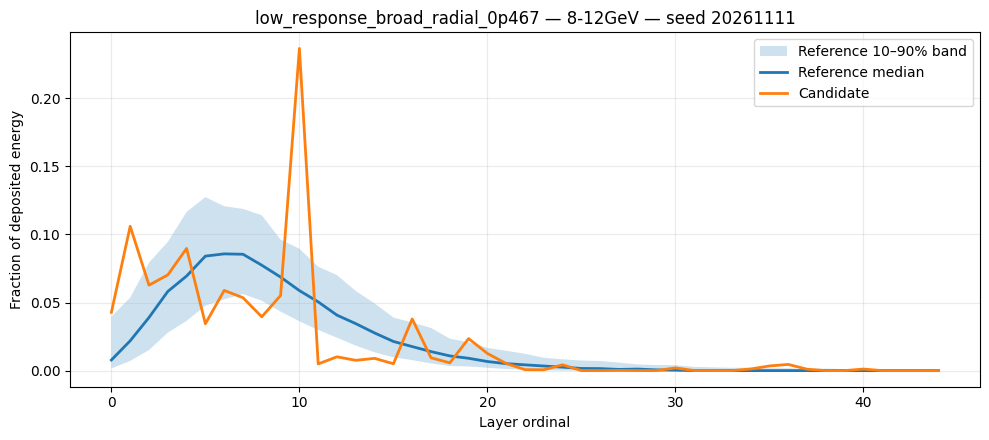

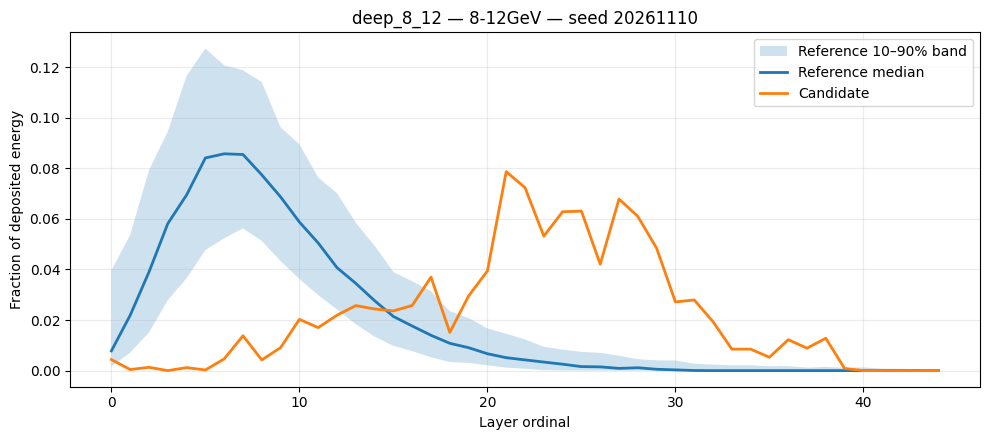

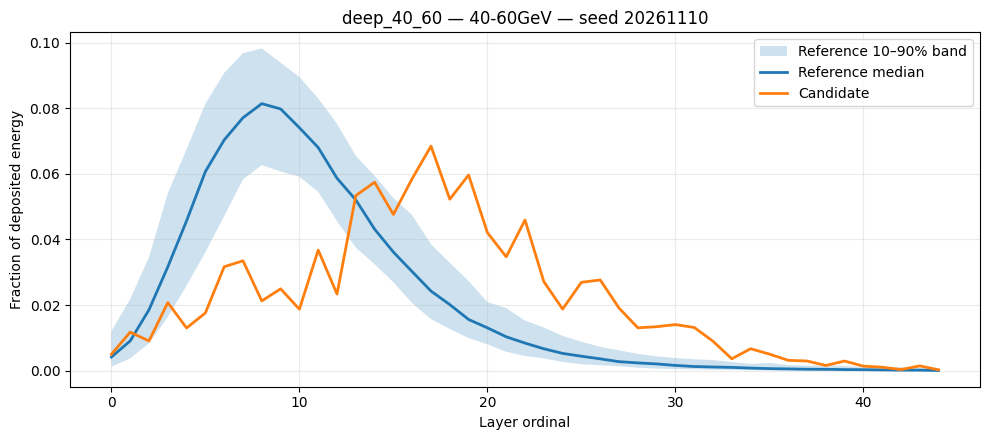

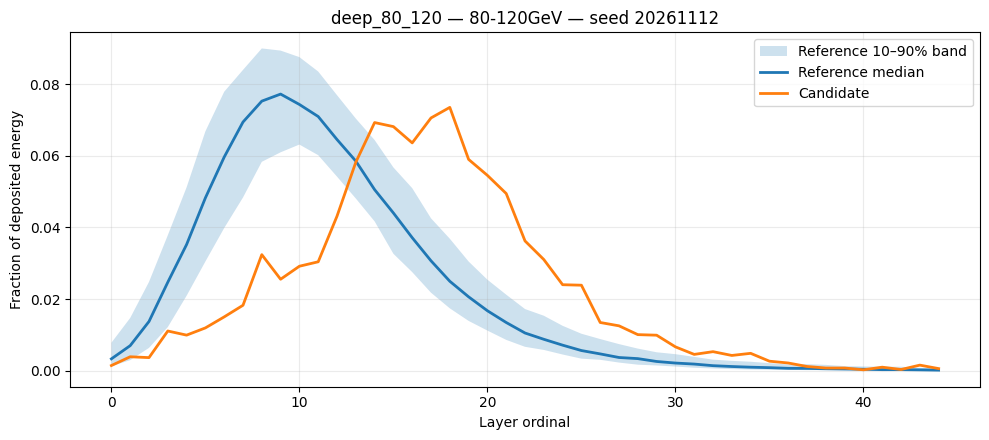

In [ ]:
# 17. Plot candidate longitudinal profiles against reference distribution
for label, ev in candidate_events.items():
    ref = reference_native(EXPECTED_SEEDS[0], ev["stratum"])
    ref_profiles = np.stack([layer_profile(x) for x in ref["native"]])
    candidate_profile = layer_profile(ev["native"])
    x = np.arange(N_LAYERS)
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.fill_between(x, np.quantile(ref_profiles, .10, axis=0),
                    np.quantile(ref_profiles, .90, axis=0), alpha=.22,
                    label="Reference 10–90% band")
    ax.plot(x, np.median(ref_profiles, axis=0), linewidth=2, label="Reference median")
    ax.plot(x, candidate_profile, linewidth=2, label="Candidate")
    ax.set(xlabel="Layer ordinal", ylabel="Fraction of deposited energy",
           title=f"{label} — {ev['stratum']} — seed {ev['seed']}")
    ax.grid(alpha=.25); ax.legend(); plt.tight_layout(); plt.show()


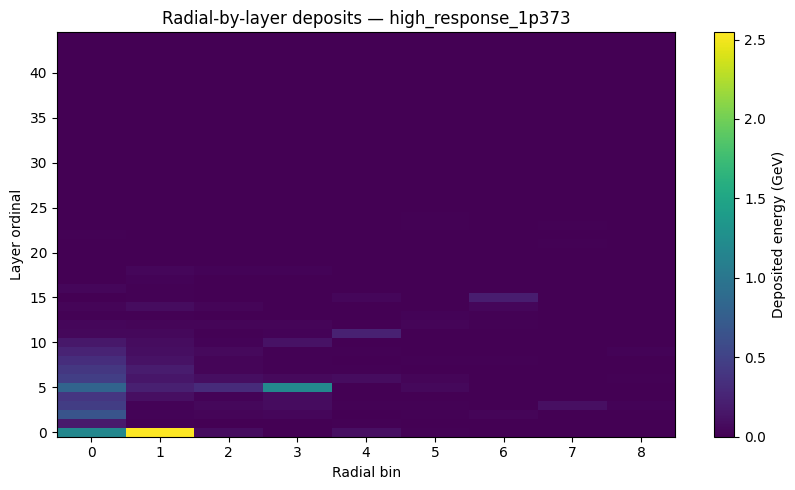

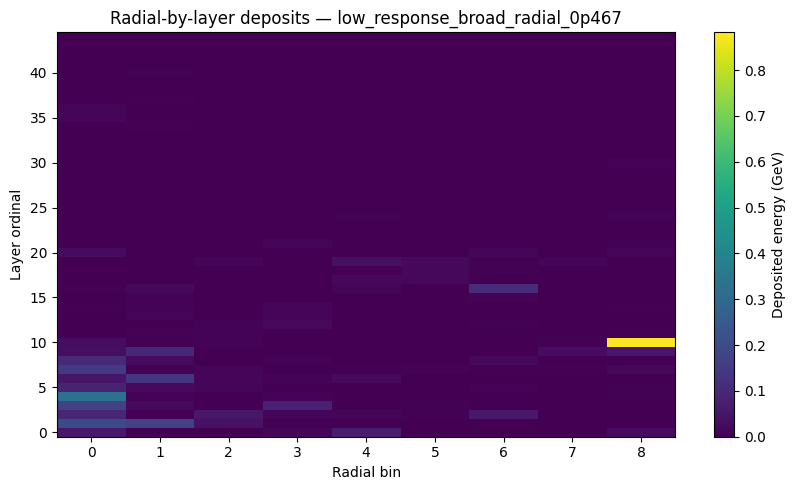

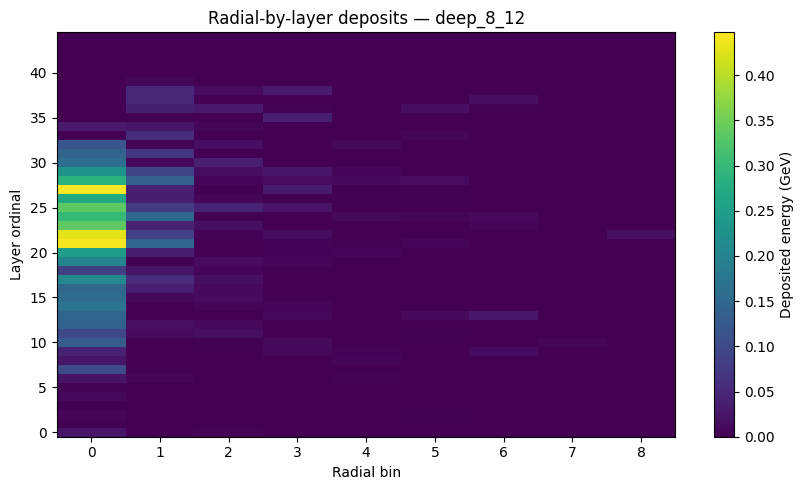

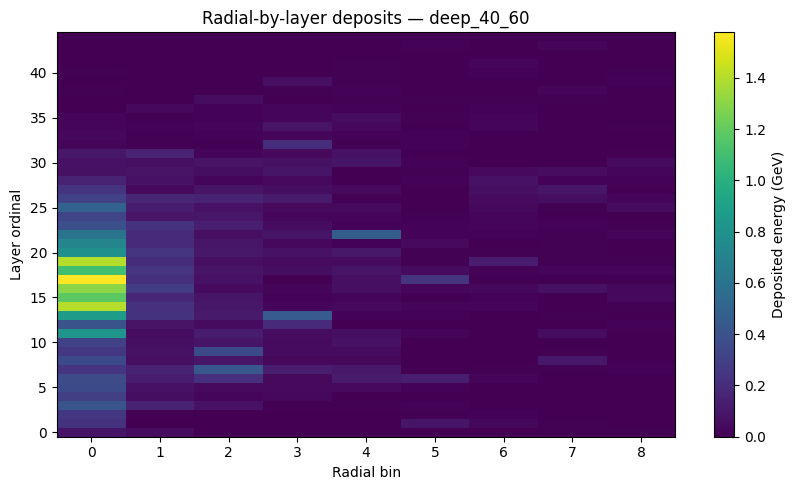

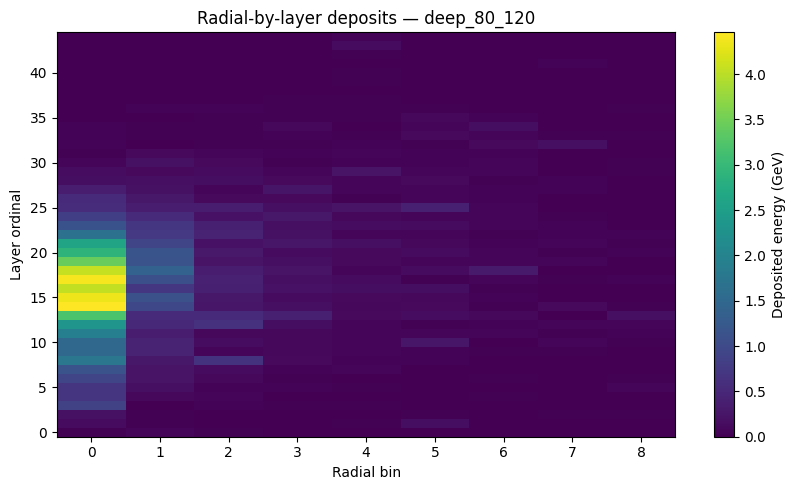

In [ ]:
# 18. Candidate radial-by-layer maps (sum over angular bins)
for label, ev in candidate_events.items():
    heat = radial_layer_profile(ev["native"])
    fig, ax = plt.subplots(figsize=(8.5, 5))
    im = ax.imshow(heat, aspect="auto", origin="lower", interpolation="nearest")
    ax.set(xlabel="Radial bin", ylabel="Layer ordinal",
           title=f"Radial-by-layer deposits — {label}")
    fig.colorbar(im, ax=ax, label="Deposited energy (GeV)")
    plt.tight_layout(); plt.show()


## 9. Cross-seed population check

A candidate can be dramatic but isolated. This section compares event-level depth, response and radial-RMS distributions across all seeds, and counts the frequency of deposits in the low-response event's hotspot cell and its layer-10 outer radial ring.

In [ ]:
# 19. Event-level metrics across reference, generator and scale-only
population_rows = []
for window in ENERGY_WINDOWS:
    for method in ["reference", "generator", "scale_only"]:
        if method == "generator":
            blocks = []
            for seed in EXPECTED_SEEDS:
                for r in [0, 1]:
                    blocks.append((seed, runs[seed]["arrays"][window][f"generator_run{r}"]))
        else:
            blocks = [("fixed", runs[EXPECTED_SEEDS[0]]["arrays"][window][method])]
        for seed, block in blocks:
            for i, (native, e) in enumerate(zip(block["native"], block["energy"])):
                met = metrics_from_native(native, e)
                population_rows.append({"energy_window": window, "method": method,
                                        "generation_seed": seed, "row": i, **met})

population_metrics = pd.DataFrame(population_rows)
population_summary = population_metrics.groupby(["energy_window", "method"]).agg(
    n=("response", "size"),
    response_mean=("response", "mean"),
    response_std=("response", "std"),
    response_q01=("response", lambda x: x.quantile(.01)),
    response_q99=("response", lambda x: x.quantile(.99)),
    depth_median=("depth_layer", "median"),
    depth_q99=("depth_layer", lambda x: x.quantile(.99)),
    r_rms_median=("r_rms", "median"),
    r_rms_q99=("r_rms", lambda x: x.quantile(.99)),
).reset_index()
display(population_summary.round(6))


,energy_window,method,n,response_mean,response_std,response_q01,response_q99,depth_median,depth_q99,r_rms_median,r_rms_q99
0,40-60GeV,generator,1800,0.769100,0.051742,0.652575,0.889296,10.478610,13.873968,10.523035,12.885929
1,40-60GeV,reference,300,0.773082,0.045572,0.658243,0.864275,10.560139,14.362103,10.714516,13.333534
2,40-60GeV,scale_only,300,0.777284,0.049562,0.662566,0.881350,10.540177,14.021276,10.922265,13.080035
3,8-12GeV,generator,1800,0.751150,0.111587,0.483636,0.989274,8.463668,12.098403,10.086040,16.325141
4,8-12GeV,reference,300,0.765908,0.098617,0.512927,0.971231,8.551850,13.365178,10.517458,16.937494
5,8-12GeV,scale_only,300,0.777275,0.049563,0.662558,0.881342,10.540006,14.021217,10.922107,13.079328
6,80-120GeV,generator,1800,0.773084,0.036895,0.688889,0.857673,11.363967,14.902735,10.663957,12.395004
7,80-120GeV,reference,300,0.778580,0.034549,0.689302,0.846611,11.566918,14.624557,10.897021,12.660584
8,80-120GeV,scale_only,300,0.777284,0.049562,0.662566,0.881350,10.540175,14.021276,10.922267,13.080035


In [ ]:
# 20. Seed-level stability of the three diagnostic metrics
seed_stability_rows = []
for window in ENERGY_WINDOWS:
    for seed in EXPECTED_SEEDS:
        rows = population_metrics[(population_metrics.energy_window == window) &
                                  (population_metrics.method == "generator") &
                                  (population_metrics.generation_seed == seed)]
        seed_stability_rows.append({
            "energy_window": window, "seed": seed, "n": len(rows),
            "response_mean": rows.response.mean(), "response_std": rows.response.std(),
            "depth_median": rows.depth_layer.median(), "depth_q99": rows.depth_layer.quantile(.99),
            "r_rms_median": rows.r_rms.median(), "r_rms_q99": rows.r_rms.quantile(.99),
        })
seed_stability = pd.DataFrame(seed_stability_rows)
display(seed_stability.round(6))


,energy_window,seed,n,response_mean,response_std,depth_median,depth_q99,r_rms_median,r_rms_q99
0,8-12GeV,20261110,600,0.746072,0.111820,8.422337,11.851834,10.131231,16.412105
1,8-12GeV,20261111,600,0.746058,0.114067,8.426161,11.848648,10.101884,16.296109
2,8-12GeV,20261112,600,0.761321,0.108287,8.515322,12.476368,10.029931,16.225545
3,40-60GeV,20261110,600,0.766920,0.050167,10.474279,14.672439,10.524939,12.865037
4,40-60GeV,20261111,600,0.770958,0.051073,10.455245,13.999325,10.568404,12.888288
5,40-60GeV,20261112,600,0.769422,0.053918,10.535075,13.547687,10.462533,12.844707
6,80-120GeV,20261110,600,0.771321,0.035373,11.342073,15.264691,10.682163,12.512423
7,80-120GeV,20261111,600,0.775643,0.038097,11.328493,14.561757,10.642178,12.401351
8,80-120GeV,20261112,600,0.772287,0.037084,11.401332,14.859335,10.671283,12.178938


## 10. Interpretation checklist

Use these rules when reading the outputs:
- **High response:** first confirm incident and deposited energies are in the same units and reproduce the saved response. Then inspect the per-cell contribution pattern. A response above 1 is not automatically a unit or decoder bug.
- **Outer-cell hotspot:** compare the exact cell, the whole angular ring in the same layer, and the same radial shell across the detector. A single exceptional cell is not evidence of a population-wide radial problem.
- **Deep showers:** compare candidate layer fractions with the reference event-level band and depth quantiles. A deep tail event does not imply the average profile is wrong.
- **Do not remove flagged events from primary metrics.** Counterfactual removal is sensitivity analysis only.
- **Do not call a shower physically impossible** using only a 300-event reference sample. Reference maxima are sample maxima, not physical limits.

In [ ]:
# 21. Automatic findings summary
findings = []

# High-response event
hmet = metrics_from_native(high["native"], high["energy"])
high_top1 = float(top_cells_high.iloc[0]["energy_GeV"])
high_top5_fraction = float(top_cells_high.head(5)["fraction_of_total_deposit"].sum())
high_max_ref = float(candidate_metrics.loc[candidate_metrics.label == "high_response_1p373", "ref_response_max"].iloc[0])
findings.append({"topic": "High-response candidate",
                 "finding": f"Response {hmet['response']:.3f}; reference sample maximum {high_max_ref:.3f}; top cell {high_top1:.3f} GeV; top-five cells carry {high_top5_fraction:.1%} of deposit.",
                 "interpretation": "Large front-loaded local deposits contribute, but removing the top cell alone does not remove the over-response. The archived arrays do not contain the pre-decoder latent tensor, so a full replay is not possible here."})

# Low-response hotspot
lmet = metrics_from_native(low["native"], low["energy"])
hotspot_value = float(low_native[HOTSPOT_INDEX])
ring_events = {}
for window in ENERGY_WINDOWS:
    gen_exact = recurrence_samples[(window, "generator")]["exact"]
    ring_events[window] = int(np.sum(gen_exact >= 0.1))
findings.append({"topic": "Low-response / broad-radial candidate",
                 "finding": f"Response {lmet['response']:.3f}; radial RMS {lmet['r_rms']:.2f}; hotspot cell {HOTSPOT_INDEX} carries {hotspot_value:.3f} GeV ({hotspot_value/low_total:.1%} of deposit).",
                 "interpretation": "The localized cell is a major contributor to this event's radial RMS. The radial sensitivity tests are diagnostic only; original events remain in the population metrics."})

# Recurrence statement
for window in ENERGY_WINDOWS:
    exact = recurrence_samples[(window, "generator")]["exact"]
    findings.append({"topic": f"Exact hotspot recurrence — {window}",
                     "finding": f"Generator events with exact cell deposit >=0.1 GeV: {int(np.sum(exact >= .1))}/{len(exact)}.",
                     "interpretation": "Compare with reference and scale-only rows in hotspot_recurrence before describing this as recurrent or population-wide."})

# Deep events
for _, row in depth_summary[depth_summary.label.str.startswith("deep_")].iterrows():
    findings.append({"topic": f"Deep-shower candidate — {row['energy_window']}",
                     "finding": f"Depth {row['depth_layer']:.2f}; reference q99 {row['reference_depth_q99']:.2f}; reference max {row['reference_depth_max']:.2f}; depth percentile {row['candidate_depth_percentile']:.1f}.",
                     "interpretation": "A high reference percentile indicates a longitudinal tail candidate, not automatically an impossible shower."})

findings_df = pd.DataFrame(findings)
display(findings_df)


,topic,finding,interpretation
0,High-response candidate,Response 1.373; reference sample maximum 1.022...,"Large front-loaded local deposits contribute, ..."
1,Low-response / broad-radial candidate,Response 0.467; radial RMS 23.43; hotspot cell...,The localized cell is a major contributor to t...
2,Exact hotspot recurrence — 8-12GeV,Generator events with exact cell deposit >=0.1...,Compare with reference and scale-only rows in ...
3,Exact hotspot recurrence — 40-60GeV,Generator events with exact cell deposit >=0.1...,Compare with reference and scale-only rows in ...
4,Exact hotspot recurrence — 80-120GeV,Generator events with exact cell deposit >=0.1...,Compare with reference and scale-only rows in ...
5,Deep-shower candidate — 8-12GeV,Depth 22.53; reference q99 13.37; reference ma...,A high reference percentile indicates a longit...
6,Deep-shower candidate — 40-60GeV,Depth 16.85; reference q99 14.36; reference ma...,A high reference percentile indicates a longit...
7,Deep-shower candidate — 80-120GeV,Depth 16.71; reference q99 14.62; reference ma...,A high reference percentile indicates a longit...


In [ ]:
# 22. Export explicit per-layer and layer-by-radial tables for each candidate
candidate_layer_profile_rows = []
candidate_layer_radial_rows = []
for label, ev in candidate_events.items():
    prof = layer_profile(ev["native"])
    total = metrics_from_native(ev["native"], ev["energy"])["deposit_GeV"]
    layer_energy = prof * total
    radial_energy = radial_layer_profile(ev["native"])
    ref = reference_native(EXPECTED_SEEDS[0], ev["stratum"])
    ref_profiles = np.stack([layer_profile(x) for x in ref["native"]])
    for layer in range(N_LAYERS):
        candidate_layer_profile_rows.append({
            "candidate": label, "seed": ev["seed"], "energy_window": ev["stratum"],
            "layer_ordinal": layer, "candidate_energy_GeV": layer_energy[layer],
            "candidate_fraction": prof[layer],
            "reference_fraction_median": np.median(ref_profiles[:,layer]),
            "reference_fraction_q10": np.quantile(ref_profiles[:,layer], .10),
            "reference_fraction_q90": np.quantile(ref_profiles[:,layer], .90),
        })
        for radial_bin in range(N_RADIAL):
            candidate_layer_radial_rows.append({
                "candidate": label, "seed": ev["seed"], "energy_window": ev["stratum"],
                "layer_ordinal": layer, "radial_bin": radial_bin,
                "r_low_XML": radial_edges[layer][radial_bin],
                "r_high_XML": radial_edges[layer][radial_bin+1],
                "energy_GeV": radial_energy[layer, radial_bin],
            })

candidate_layer_profiles = pd.DataFrame(candidate_layer_profile_rows)
candidate_layer_radial = pd.DataFrame(candidate_layer_radial_rows)
print("Candidate layer-profile rows:", len(candidate_layer_profiles))
print("Candidate layer/radial rows:", len(candidate_layer_radial))
display(candidate_layer_profiles.head(10))
display(candidate_layer_radial.head(10))


Candidate layer-profile rows: 225
Candidate layer/radial rows: 2025


,candidate,seed,energy_window,layer_ordinal,candidate_energy_GeV,candidate_fraction,reference_fraction_median,reference_fraction_q10,reference_fraction_q90
0,high_response_1p373,20261111,8-12GeV,0,3.920769,0.292190,0.007787,0.001595,0.039621
1,high_response_1p373,20261111,8-12GeV,1,0.226827,0.016904,0.021900,0.007122,0.053632
2,high_response_1p373,20261111,8-12GeV,2,0.827561,0.061673,0.039016,0.015114,0.079273
3,high_response_1p373,20261111,8-12GeV,3,0.787677,0.058701,0.058144,0.027847,0.094527
4,high_response_1p373,20261111,8-12GeV,4,0.617487,0.046017,0.069476,0.036532,0.116528
5,high_response_1p373,20261111,8-12GeV,5,2.596456,0.193497,0.084111,0.047710,0.127422
6,high_response_1p373,20261111,8-12GeV,6,0.921912,0.068704,0.085751,0.052349,0.120727
7,high_response_1p373,20261111,8-12GeV,7,0.659425,0.049143,0.085475,0.056273,0.118774
8,high_response_1p373,20261111,8-12GeV,8,0.555298,0.041383,0.077410,0.051291,0.114106
9,high_response_1p373,20261111,8-12GeV,9,0.473724,0.035304,0.068700,0.043365,0.096202


,candidate,seed,energy_window,layer_ordinal,radial_bin,r_low_XML,r_high_XML,energy_GeV
0,high_response_1p373,20261111,8-12GeV,0,0,0.00,4.65,1.178129
1,high_response_1p373,20261111,8-12GeV,0,1,4.65,9.30,2.545314
2,high_response_1p373,20261111,8-12GeV,0,2,9.30,13.95,0.080850
3,high_response_1p373,20261111,8-12GeV,0,3,13.95,18.60,0.000000
4,high_response_1p373,20261111,8-12GeV,0,4,18.60,23.25,0.100368
5,high_response_1p373,20261111,8-12GeV,0,5,23.25,27.90,0.014227
6,high_response_1p373,20261111,8-12GeV,0,6,27.90,32.55,0.001881
7,high_response_1p373,20261111,8-12GeV,0,7,32.55,37.20,0.000000
8,high_response_1p373,20261111,8-12GeV,0,8,37.20,41.85,0.000000
9,high_response_1p373,20261111,8-12GeV,1,0,0.00,4.65,0.181674


## 12. What this archive-based investigation cannot prove

1. It cannot replay the complete denoising sampler-to-decoder path because the ZIP files do not contain the pre-decoder latent tensor for these specific events.
2. It cannot establish that the reference cache was excluded from checkpoint training or checkpoint selection. The manifests explicitly leave that status unverified.
3. It cannot establish physical impossibility from a finite reference sample. It can identify statistical differences and candidate anomalies.
4. It does not justify deleting unusual events or retraining the model. Keep the full sample for the primary fidelity results.

In [ ]:
# 23. Export tables, plots and a concise audit report
OUT_DIR = Path("/content/electron_technical_investigation")
FIG_DIR = OUT_DIR / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Export analysis tables
exports = {
    "run_compatibility.csv": compatibility,
    "source_hash_audit.csv": source_audit,
    "candidate_ids.csv": candidate_id_table,
    "candidate_metric_reference_comparison.csv": candidate_metrics,
    "high_response_top_cells.csv": top_cells_high,
    "low_response_top_cells.csv": low_top_cells,
    "low_response_radial_sensitivity.csv": low_sensitivity,
    "hotspot_recurrence.csv": hotspot_recurrence,
    "candidate_depth_summary.csv": depth_summary,
    "population_metrics.csv": population_metrics,
    "population_summary.csv": population_summary,
    "generation_seed_stability.csv": seed_stability,
    "automatic_findings.csv": findings_df,
    "candidate_layer_profiles.csv": candidate_layer_profiles,
    "candidate_layer_radial_energy.csv": candidate_layer_radial,
}
for filename, df in exports.items():
    df.to_csv(OUT_DIR / filename, index=False)

# Save key figures already displayed: recreate to persist with deterministic names.
for label, ev in candidate_events.items():
    ref = reference_native(EXPECTED_SEEDS[0], ev["stratum"])
    ref_profiles = np.stack([layer_profile(x) for x in ref["native"]])
    profile = layer_profile(ev["native"])
    x = np.arange(N_LAYERS)
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.fill_between(x, np.quantile(ref_profiles, .10, axis=0), np.quantile(ref_profiles, .90, axis=0), alpha=.22, label="Reference 10–90%")
    ax.plot(x, np.median(ref_profiles, axis=0), linewidth=2, label="Reference median")
    ax.plot(x, profile, linewidth=2, label="Candidate")
    ax.set(xlabel="Layer ordinal", ylabel="Fraction of deposited energy", title=f"{label} — {ev['stratum']} — seed {ev['seed']}")
    ax.grid(alpha=.25); ax.legend(); plt.tight_layout()
    fig.savefig(FIG_DIR / f"{label}_layer_profile.png", dpi=160)
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(8.5, 5))
    im = ax.imshow(radial_layer_profile(ev["native"]), aspect="auto", origin="lower", interpolation="nearest")
    ax.set(xlabel="Radial bin", ylabel="Layer ordinal", title=f"Radial-by-layer deposits — {label}")
    fig.colorbar(im, ax=ax, label="Deposited energy (GeV)")
    plt.tight_layout(); fig.savefig(FIG_DIR / f"{label}_radial_layer_map.png", dpi=160); plt.close(fig)

# Store the candidate-specific normalized energy fraction diagnostic.
np.savez_compressed(
    OUT_DIR / "candidate_native_arrays.npz",
    **{label: ev["native"].astype(np.float32) for label, ev in candidate_events.items()}
)

report_lines = [
    "# Electron Technical Investigation Report",
    "",
    f"Generation seeds: {EXPECTED_SEEDS}",
    f"Analysis cutoff: {ANALYSIS_CUT_GEV} GeV",
    f"Checkpoint SHA-256: {base_manifest['checkpoints']['electron']['sha256']}",
    f"Reference SHA-256: {base_manifest['reference_files']['electron']['sha256']}",
    f"Repository revision: {base_manifest['revision']}",
    "",
    "## Compatibility",
    f"All three runs share the same partition hash: {base_manifest['partition_sha256']['electron']}.",
    "The ZIPs contain identical reference arrays, event IDs, scale-only arrays and donor tables across seeds.",
    "",
    "## Principal technical findings",
]
for _, row in findings_df.iterrows():
    report_lines += [f"### {row['topic']}", str(row['finding']), str(row['interpretation']), ""]
report_lines += [
    "## Limitations",
    "- The high-response event has response above one, but its saved incident/deposited energies are both in GeV and the response identity checks; the source decoder scales cells individually and does not impose a final global sum-equals-incident-energy constraint.",
    "- Full pre-decoder sampler replay is unavailable because pre-decoder tensors are not included in these ZIP files.",
    "- Reference/checkpoint training and selection independence is unverified.",
    "- Reference sample maxima are not physical impossibility limits.",
    "- Outlier-removal calculations are sensitivity diagnostics only; primary results retain all events.",
]
(OUT_DIR / "electron_technical_investigation_report.md").write_text("\n".join(report_lines), encoding="utf-8")

zip_out = Path("/content/electron_technical_investigation_results.zip")
with zipfile.ZipFile(zip_out, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in OUT_DIR.rglob("*"):
        if path.is_file():
            zf.write(path, arcname=path.relative_to(OUT_DIR))

print("Saved results:", zip_out)
print("Files included:", sum(1 for p in OUT_DIR.rglob("*") if p.is_file()))


Saved results: /content/electron_technical_investigation_results.zip
Files included: 27


In [ ]:
# 24. Download the results bundle
from google.colab import files
files.download("/content/electron_technical_investigation_results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Recommended interpretation / stopping decision

After reviewing the exported results:
- If the high-response event's saved energy and incident energy are in GeV and the response identity matches, there is no simple unit mismatch in the archived outputs. The source audit explains the cell-wise inverse scaling and why a global response above one is not prohibited by a global energy-normalisation step.
- If the exact hotspot is rare while the broader radial ring and whole outer shell are close to reference, classify it as a localized candidate outlier, not general radial broadening.
- If deep candidate profiles are outside the reference tail but the mean 45-layer profile stays close, classify them as rare longitudinal outliers rather than a global shower-depth failure.
- Keep all events in primary fidelity metrics. Do not retrain solely because these examples exist.

The electron diagnostic phase can be closed once these tables are reviewed and the reference-data provenance question is addressed with the checkpoint maintainer.